In [1]:
# Import Libraries and Load Preprocessed Data
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

# Load the cleaned dataset from Week 1
df = pd.read_csv("titanic_cleaned.csv")
print("Data Shape:", df.shape)
df.head()

Data Shape: (891, 9)


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,-0.565736,1,0,-0.502445,1,0,1
1,1,1,0.663861,1,0,0.786845,0,0,0
2,1,3,-0.258337,0,0,-0.488854,0,0,1
3,1,1,0.433312,1,0,0.420730,0,0,1
4,0,3,0.433312,0,0,-0.486337,1,0,1


In [2]:
# Split Data into Features (X), Target (y)z and Train/Test Sets
# We separate the independent variables (X) from the target column (y= Supervised). We then split into 80% training data (to learn patterns) and 20% test data (unseen data to evaluate accuracy.)

# Separate features and target
X = df.drop(columns=["Survived"])
y = df["Survived"]

# Split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

Training samples: 712
Testing samples: 179


In [3]:
# Tain Model 1- Logistic Regression
# A statistical linear model estimating probability of class membership using a sigmoid activation function.

#Initiate and train Logistic Regression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)

#Predict on test set
lr_preds= lr_model.predict(X_test)

#Calculate metrics
lr_acc = accuracy_score(y_test, lr_preds)
lr_prec = precision_score(y_test, lr_preds)
lr_rec = recall_score(y_test, lr_preds)
lr_f1 = f1_score(y_test, lr_preds)

print("=== Logistic Regression Metrics ===")
print(f"Accuracy : {lr_acc:.4f}")
print(f"Precision: {lr_prec:.4f}")
print(f"Recall   : {lr_rec:.4f}")
print(f"F1-Score : {lr_f1:.4f}")

=== Logistic Regression Metrics ===
Accuracy : 0.8045
Precision: 0.7931
Recall   : 0.6667
F1-Score : 0.7244


In [4]:
# Train Model 2- Random Forest Classifier
# An ensemble algorithm combining multiple decision trees trained on bootstrap samples to reduce variance and capture non-linear relationships.

# Initialize and train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on test set
rf_preds = rf_model.predict(X_test)

# Calculate metrics
rf_acc = accuracy_score(y_test, rf_preds)
rf_prec = precision_score(y_test, rf_preds)
rf_rec = recall_score(y_test, rf_preds)
rf_f1 = f1_score(y_test, rf_preds)

print("=== Random Forest Metrics ===")
print(f"Accuracy : {rf_acc:.4f}")
print(f"Precision: {rf_prec:.4f}")
print(f"Recall   : {rf_rec:.4f}")
print(f"F1-Score : {rf_f1:.4f}")

=== Random Forest Metrics ===
Accuracy : 0.8156
Precision: 0.7812
Recall   : 0.7246
F1-Score : 0.7519


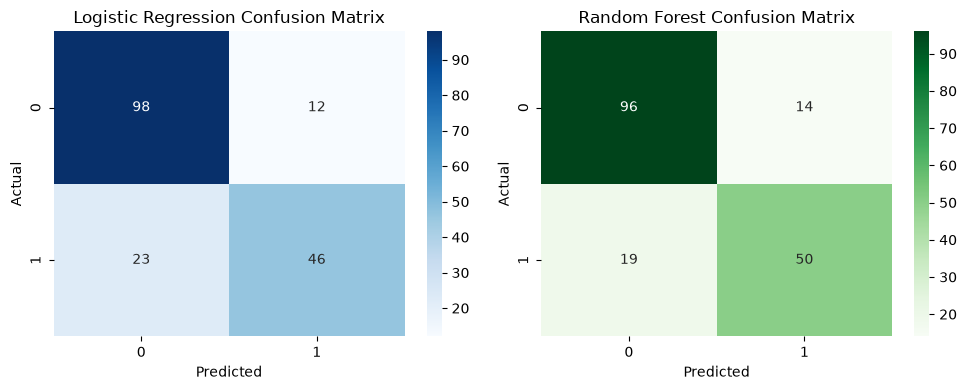

In [6]:
# Confusion Matrices Visualization
# Evaluates where models made correct prediction vs. False Positives (Type I error) and False Negatives (Type II error).

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Logistic Regression Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, lr_preds),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, rf_preds),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1],
)
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [7]:
# Side-by-Side Model Comparison Table
# Creating the direct comparison deliverable required for the report.

# Create comparison DataFrame
comparison_df = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
        "Logistic Regression": [lr_acc, lr_prec, lr_rec, lr_f1],
        "Random Forest": [rf_acc, rf_prec, rf_rec, rf_f1],
    }
)

# Format to percentage style
comparison_df["Logistic Regression"] = (
    comparison_df["Logistic Regression"] * 100
).round(2).astype(str) + "%"
comparison_df["Random Forest"] = (
    comparison_df["Random Forest"] * 100
).round(2).astype(str) + "%"

print("=== Model Performance Comparison ===")
display(comparison_df)

=== Model Performance Comparison ===


,Metric,Logistic Regression,Random Forest
0,Accuracy,80.45%,81.56%
1,Precision,79.31%,78.12%
2,Recall,66.67%,72.46%
3,F1-Score,72.44%,75.19%
